In [1]:
import pandas as pd
import numpy as np
import json
import os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import accuracy_score, classification_report
import xgboost as xgb
import joblib
import warnings
warnings.filterwarnings("ignore")
print("✅ Imports done!")

df = pd.read_csv(
    r"C:\Users\Jyoti Hanagandi\OneDrive\Desktop\cyber_threat_detection\data\features.csv"
)

with open(
    r"C:\Users\Jyoti Hanagandi\OneDrive\Desktop\cyber_threat_detection\data\class_weights.json"
) as f:
    class_weights = json.load(f)

X = df.drop("label", axis=1)
y = df["label"]

print(f"Features shape: {X.shape}")
print(f"Class weights: {class_weights}")

# ── Three-way split: train / calibration / test ──
# Models train on X_train, get their confidence scores fixed on X_calib,
# and get evaluated on X_test — which stays completely untouched by
# training or calibration, so the reported accuracy stays honest.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full
)
print(f"Training set:     {X_train.shape}")
print(f"Calibration set:  {X_calib.shape}")
print(f"Test set:         {X_test.shape}")

print("Training Random Forest...")
print("This takes 3-5 minutes...")
rf_model = RandomForestClassifier(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1, class_weight={0: class_weights["0"], 1: class_weights["1"]})
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_acc = accuracy_score(y_test, rf_pred)
print(f"\n✅ Random Forest trained! Accuracy: {rf_acc*100:.2f}%")
print(classification_report(y_test, rf_pred, target_names=["Safe", "Malicious"]))

print("Training XGBoost...")
scale_pos_weight = len(y_train[y_train==0]) / len(y_train[y_train==1])
xgb_model = xgb.XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1, scale_pos_weight=scale_pos_weight, eval_metric="logloss", verbosity=0)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_acc = accuracy_score(y_test, xgb_pred)
print(f"\n✅ XGBoost trained! Accuracy: {xgb_acc*100:.2f}%")
print(classification_report(y_test, xgb_pred, target_names=["Safe", "Malicious"]))

# ── Calibration — fixes the "98% confidence on everything" problem ──
# RF and XGBoost's raw predict_proba() is just tree-vote fractions, not a
# true probability, so it tends to be overconfident. FrozenEstimator marks
# the already-trained model as "don't refit me" — CalibratedClassifierCV
# then just learns a confidence-correction curve on the calibration set,
# without retraining the underlying RF/XGBoost model at all.
print("\nCalibrating models...")
calibrated_rf = CalibratedClassifierCV(FrozenEstimator(rf_model), method="sigmoid")
calibrated_rf.fit(X_calib, y_calib)

calibrated_xgb = CalibratedClassifierCV(FrozenEstimator(xgb_model), method="sigmoid")
calibrated_xgb.fit(X_calib, y_calib)

# Sanity check — calibrated accuracy should be very close to the raw
# model's accuracy (calibration adjusts confidence, not the verdict itself)
calibrated_rf_pred = calibrated_rf.predict(X_test)
calibrated_xgb_pred = calibrated_xgb.predict(X_test)
calibrated_rf_acc = accuracy_score(y_test, calibrated_rf_pred)
calibrated_xgb_acc = accuracy_score(y_test, calibrated_xgb_pred)
print(f"✅ Calibrated Random Forest accuracy: {calibrated_rf_acc*100:.2f}% (raw was {rf_acc*100:.2f}%)")
print(f"✅ Calibrated XGBoost accuracy:       {calibrated_xgb_acc*100:.2f}% (raw was {xgb_acc*100:.2f}%)")

import os
import joblib

os.makedirs("../models", exist_ok=True)

# Save the CALIBRATED models — these are what main.py will load.
# They still support .predict_proba(), so no backend changes are needed.
joblib.dump(calibrated_rf, "../models/random_forest.pkl")
joblib.dump(calibrated_xgb, "../models/xgboost.pkl")

print("✅ Both calibrated models saved!")
print(f"\nRandom Forest: {calibrated_rf_acc*100:.2f}%")
print(f"XGBoost:       {calibrated_xgb_acc*100:.2f}%")

RF_WEIGHT  = 0.55
XGB_WEIGHT = 0.45
rf_proba       = calibrated_rf.predict_proba(X_test)[:, 1]
xgb_proba      = calibrated_xgb.predict_proba(X_test)[:, 1]
ensemble_proba = RF_WEIGHT * rf_proba + XGB_WEIGHT * xgb_proba
ensemble_pred  = (ensemble_proba >= 0.5).astype(int)
ensemble_acc = accuracy_score(y_test, ensemble_pred)
print(f"Random Forest: {calibrated_rf_acc*100:.2f}%")
print(f"XGBoost:       {calibrated_xgb_acc*100:.2f}%")
print(f"Ensemble:      {ensemble_acc*100:.2f}%")
ensemble_config = {"rf_weight": RF_WEIGHT, "xgb_weight": XGB_WEIGHT, "rf_accuracy": calibrated_rf_acc, "xgb_accuracy": calibrated_xgb_acc, "ensemble_accuracy": ensemble_acc, "threshold": 0.5}
with open("../models/ensemble_config.json","w") as f:
    json.dump(ensemble_config, f, indent=2)

print("\n✅ STEP 4 + 5 COMPLETE! (Calibrated)")
print("Run step7_evaluation.ipynb next to regenerate metrics.json,")
print("the confusion matrix, and the ROC curve for the calibrated models.")

✅ Imports done!
Features shape: (641119, 11)
Class weights: {'0': 0.7488308260138292, '1': 1.5046986701965368}
Training set:     (410316, 11)
Calibration set:  (102579, 11)
Test set:         (128224, 11)
Training Random Forest...
This takes 3-5 minutes...

✅ Random Forest trained! Accuracy: 94.23%
              precision    recall  f1-score   support

        Safe       0.96      0.95      0.96     85616
   Malicious       0.90      0.93      0.91     42608

    accuracy                           0.94    128224
   macro avg       0.93      0.94      0.94    128224
weighted avg       0.94      0.94      0.94    128224

Training XGBoost...

✅ XGBoost trained! Accuracy: 93.42%
              precision    recall  f1-score   support

        Safe       0.96      0.94      0.95     85616
   Malicious       0.89      0.92      0.90     42608

    accuracy                           0.93    128224
   macro avg       0.92      0.93      0.93    128224
weighted avg       0.94      0.93      0.93  

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# Store accuracy values
rf_accuracies = []
xgb_accuracies = []
iterations = range(1, 101)

# ---------------- RANDOM FOREST ----------------

rf = RandomForestClassifier(
    n_estimators=1,
    max_depth=20,
    random_state=42,
    n_jobs=-1,
    class_weight={0: 0.748830826, 1: 1.504698671},
    warm_start=True
)

for i in iterations:
    rf.set_params(n_estimators=i)
    rf.fit(X_train, y_train)

    predictions = rf.predict(X_test)
    accuracy = accuracy_score(y_test, predictions) * 100

    rf_accuracies.append(accuracy)


# ---------------- XGBOOST ----------------

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=(
        len(y_train[y_train == 0]) /
        len(y_train[y_train == 1])
    ),
    eval_metric="logloss",
    verbosity=0
)

xgb.fit(X_train, y_train)

for i in iterations:
    predictions = xgb.predict(
        X_test,
        iteration_range=(0, i)
    )

    accuracy = accuracy_score(y_test, predictions) * 100
    xgb_accuracies.append(accuracy)


# ---------------- PLOT GRAPH ----------------

plt.figure(figsize=(10, 6))

plt.plot(iterations, rf_accuracies,
         label="Random Forest", marker="o")

plt.plot(iterations, xgb_accuracies,
         label="XGBoost", marker="s")

plt.xlabel("Number of Trees / Boosting Rounds")
plt.ylabel("Accuracy (%)")
plt.title("CyberShield Model Evaluation")
plt.legend()
plt.grid(True)

plt.savefig("cybershield_accuracy_graph.png",
            dpi=300, bbox_inches="tight")

plt.show()

NameError: name 'X_train' is not defined

Train: (410316, 11) | Test: (128224, 11)
Random Forest final accuracy (100 trees): 94.23%
XGBoost final accuracy (100 rounds): 93.42%


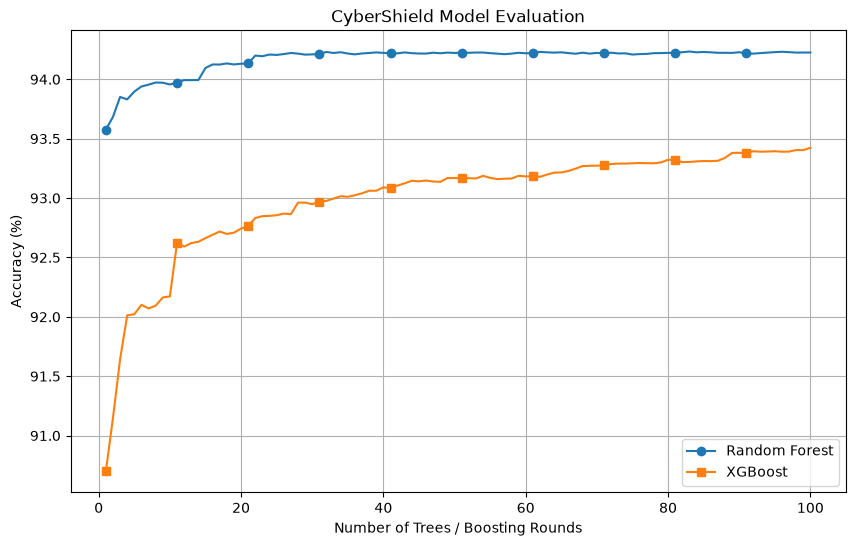

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from xgboost import XGBClassifier

# ---------------- LOAD DATA + SPLIT (same as step4_training) ----------------
df = pd.read_csv("../data/features.csv")
X = df.drop("label", axis=1)
y = df["label"]

with open("../data/class_weights.json") as f:
    class_weights = json.load(f)

# Same three-way split as step4_training, so X_test is the identical held-out test set
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_calib, y_train, y_calib = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full
)
print(f"Train: {X_train.shape} | Test: {X_test.shape}")

# Store accuracy values
rf_accuracies = []
xgb_accuracies = []
iterations = range(1, 101)

# ---------------- RANDOM FOREST ----------------
rf = RandomForestClassifier(
    n_estimators=1,
    max_depth=20,
    random_state=42,
    n_jobs=-1,
    class_weight={0: class_weights["0"], 1: class_weights["1"]},
    warm_start=True
)

for i in iterations:
    rf.set_params(n_estimators=i)
    rf.fit(X_train, y_train)

    predictions = rf.predict(X_test)
    accuracy = accuracy_score(y_test, predictions) * 100
    rf_accuracies.append(accuracy)

print(f"Random Forest final accuracy (100 trees): {rf_accuracies[-1]:.2f}%")

# ---------------- XGBOOST ----------------
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=(
        len(y_train[y_train == 0]) /
        len(y_train[y_train == 1])
    ),
    eval_metric="logloss",
    verbosity=0
)

xgb.fit(X_train, y_train)

for i in iterations:
    predictions = xgb.predict(X_test, iteration_range=(0, i))
    accuracy = accuracy_score(y_test, predictions) * 100
    xgb_accuracies.append(accuracy)

print(f"XGBoost final accuracy (100 rounds): {xgb_accuracies[-1]:.2f}%")

# ---------------- PLOT GRAPH ----------------
plt.figure(figsize=(10, 6))

plt.plot(iterations, rf_accuracies,
         label="Random Forest", marker="o", markevery=10)

plt.plot(iterations, xgb_accuracies,
         label="XGBoost", marker="s", markevery=10)

plt.xlabel("Number of Trees / Boosting Rounds")
plt.ylabel("Accuracy (%)")
plt.title("CyberShield Model Evaluation")
plt.legend()
plt.grid(True)

plt.savefig("cybershield_accuracy_graph.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

# 1. LOAD DATASET

df = pd.read_csv("features.csv")

X = df.drop("label", axis=1)
y = df["label"]

print("Dataset shape:", df.shape)


# 2. SPLIT DATASET (64:16:20)

X_train_cal, X_test, y_train_cal, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_cal, y_train, y_cal = train_test_split(
    X_train_cal, y_train_cal,
    test_size=0.20,
    random_state=42,
    stratify=y_train_cal
)

print("Training:", len(X_train))
print("Calibration:", len(X_cal))
print("Testing:", len(X_test))


# 3. RANDOM FOREST

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1,
    class_weight={
        0: 0.748830826,
        1: 1.504698671
    }
)

rf.fit(X_train, y_train)

rf_calibrated = CalibratedClassifierCV(
    FrozenEstimator(rf),
    method="sigmoid"
)

rf_calibrated.fit(X_cal, y_cal)


# 4. XGBOOST

scale = (
    len(y_train[y_train == 0]) /
    len(y_train[y_train == 1])
)

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale,
    eval_metric="logloss",
    verbosity=0
)

xgb.fit(X_train, y_train)

xgb_calibrated = CalibratedClassifierCV(
    FrozenEstimator(xgb),
    method="sigmoid"
)

xgb_calibrated.fit(X_cal, y_cal)


# 5. WEIGHTED ENSEMBLE

rf_proba = rf_calibrated.predict_proba(X_test)[:, 1]

xgb_proba = xgb_calibrated.predict_proba(X_test)[:, 1]

ensemble_proba = (
    0.55 * rf_proba +
    0.45 * xgb_proba
)

ensemble_pred = (ensemble_proba >= 0.5).astype(int)


# 6. FINAL EVALUATION METRICS

accuracy = accuracy_score(y_test, ensemble_pred) * 100

precision = precision_score(y_test, ensemble_pred) * 100

recall = recall_score(y_test, ensemble_pred) * 100

f1 = f1_score(y_test, ensemble_pred) * 100

auc = roc_auc_score(y_test, ensemble_proba) * 100


# 7. DISPLAY RESULTS

print("\n===== CYBERSHIELD FINAL EVALUATION =====")

print(f"Accuracy:  {accuracy:.2f}%")
print(f"Precision: {precision:.2f}%")
print(f"Recall:    {recall:.2f}%")
print(f"F1-score:  {f1:.2f}%")
print(f"AUC-ROC:   {auc:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ensemble_pred))

ModuleNotFoundError: No module named 'sklearn.model_selection'

In [3]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

# 1. LOAD DATASET
# (notebook lives in notebooks/, features.csv lives in data/)

df = pd.read_csv("../data/features.csv")

X = df.drop("label", axis=1)
y = df["label"]

print("Dataset shape:", df.shape)


# 2. SPLIT DATASET (64:16:20)

X_train_cal, X_test, y_train_cal, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_cal, y_train, y_cal = train_test_split(
    X_train_cal, y_train_cal,
    test_size=0.20,
    random_state=42,
    stratify=y_train_cal
)

print("Training:", len(X_train))
print("Calibration:", len(X_cal))
print("Testing:", len(X_test))


# 3. RANDOM FOREST

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1,
    class_weight={
        0: 0.748830826,
        1: 1.504698671
    }
)

rf.fit(X_train, y_train)

rf_calibrated = CalibratedClassifierCV(
    FrozenEstimator(rf),
    method="sigmoid"
)

rf_calibrated.fit(X_cal, y_cal)


# 4. XGBOOST

scale = (
    len(y_train[y_train == 0]) /
    len(y_train[y_train == 1])
)

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale,
    eval_metric="logloss",
    verbosity=0
)

xgb.fit(X_train, y_train)

xgb_calibrated = CalibratedClassifierCV(
    FrozenEstimator(xgb),
    method="sigmoid"
)

xgb_calibrated.fit(X_cal, y_cal)


# 5. WEIGHTED ENSEMBLE

rf_proba = rf_calibrated.predict_proba(X_test)[:, 1]

xgb_proba = xgb_calibrated.predict_proba(X_test)[:, 1]

ensemble_proba = (
    0.55 * rf_proba +
    0.45 * xgb_proba
)

ensemble_pred = (ensemble_proba >= 0.5).astype(int)


# 6. FINAL EVALUATION METRICS

accuracy = accuracy_score(y_test, ensemble_pred) * 100

precision = precision_score(y_test, ensemble_pred) * 100

recall = recall_score(y_test, ensemble_pred) * 100

f1 = f1_score(y_test, ensemble_pred) * 100

auc = roc_auc_score(y_test, ensemble_proba) * 100


# 7. DISPLAY RESULTS

print("\n===== CYBERSHIELD FINAL EVALUATION =====")

print(f"Accuracy:  {accuracy:.2f}%")
print(f"Precision: {precision:.2f}%")
print(f"Recall:    {recall:.2f}%")
print(f"F1-score:  {f1:.2f}%")
print(f"AUC-ROC:   {auc:.2f}%")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ensemble_pred))

ModuleNotFoundError: No module named 'sklearn.model_selection'